# TP 3 NLP -> Prompting : classer les répliques avec un LLM

Paul Pitiot, ING 3 Option IA Groupe B

## Objectif retenu

Classer les répliques de Tiny Shakespeare (quel personnage parle ?) avec un LLM local, sans entraînement : la réplique est mise dans un prompt et on mesure la réponse. Mêmes 5 locuteurs et même test que les TP 1 et 2. Étapes du sujet : 1 prompting, 2 modèle LLM, 3 sortie générée, 4 évaluation.

`réplique → prompt → LLM → texte généré → parsing → label → mesure`

Livrable : trois stratégies de prompt (zero-shot, few-shot, few-shot avec format imposé) comparées entre elles et aux scores des TP 1 et 2, avec le coût et la variabilité. Le test est réduit à 100 répliques pour limiter les appels. Les 300 réponses sont dans `nlp/cache/` : relancer le notebook ne rappelle pas le modèle (Ollama doit tout de même répondre).

## 0. Environnement et config

Tout ce qui se règle est dans la cellule du dessous, en majuscules. `PROVIDER` et `MODEL_NAME` peuvent venir de l'environnement pour changer de modèle sans toucher au notebook.

In [ ]:
%matplotlib inline

import os
import re
import json
import time
import random
import hashlib
import platform
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import sklearn
from scipy.stats import binomtest
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
)

# ---- config ----
RANDOM_STATE = 42                                    # même graine que TP1 / TP2 : même test
PROVIDER = os.environ.get("PROVIDER", "ollama")      # "ollama" en local, ou "openai" (API compatible OpenAI, clé dans l'env)
MODEL_NAME = os.environ.get("MODEL_NAME", "qwen2.5:1.5b" if PROVIDER == "ollama" else "gpt-4o-mini")
TEMPERATURE = 0                                      # classification : on veut du stable, pas du créatif 
SEED_MODELE = RANDOM_STATE                           # passé au modèle, quand le fournisseur le permet
MAX_TOKENS = 30                                      # un nom c'est 3 tokens, 30 laisse voir si le modèle bavarde
N_TEST = 100                                         # 100 répliques suffisent pour le squelette, sinon ça coûte (3 stratégies = 300 appels)
N_EXEMPLES_PAR_LOCUTEUR = 2                          # few-shot : 2 exemples par locuteur, pris dans le TRAIN
CACHE_DIR = Path("cache")                            # une réponse = un fichier, pour ne pas rappeler le modèle à chaque exécution
OLLAMA_URL = "http://localhost:11434"
API_BASE_URL = os.environ.get("API_BASE_URL", "https://api.openai.com/v1")   # Mistral, Groq... : même API, autre URL
API_KEY_ENV = "OPENAI_API_KEY"                       # le nom de la variable, jamais la clé
PRIX_USD_PAR_M_TOKENS = {"entree": 0.15, "sortie": 0.60}   # tarif indicatif d'une petite API (le modèle local ne coûte rien, c'est un ordre de grandeur)
URL_CORPUS = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
CACHE_DIR.mkdir(exist_ok=True)

print(f"python {platform.python_version()} | pandas {pd.__version__} | sklearn {sklearn.__version__} | requests {requests.__version__}")
print(f"PROVIDER = {PROVIDER} | MODEL_NAME = {MODEL_NAME} | TEMPERATURE = {TEMPERATURE} | SEED_MODELE = {SEED_MODELE} | MAX_TOKENS = {MAX_TOKENS}")
print(f"RANDOM_STATE = {RANDOM_STATE} | N_TEST = {N_TEST} | N_EXEMPLES_PAR_LOCUTEUR = {N_EXEMPLES_PAR_LOCUTEUR}")
print(f"cache : {CACHE_DIR} ({len(list(CACHE_DIR.glob('*.json')))} réponses déjà en cache)")

python 3.11.15 | pandas 3.0.5 | sklearn 1.9.0 | requests 2.34.2
PROVIDER = ollama | MODEL_NAME = qwen2.5:1.5b | TEMPERATURE = 0 | SEED_MODELE = 42 | MAX_TOKENS = 30
RANDOM_STATE = 42 | N_TEST = 100 | N_EXEMPLES_PAR_LOCUTEUR = 2
cache : cache (300 réponses déjà en cache)


## 1. Chargement du corpus et échantillon de test

Même parsing et même découpage qu'aux TP 1 et 2 : 5 locuteurs, répliques d'au moins 5 mots, `train_test_split` 80 / 20 stratifié avec `random_state = 42`. Je dois retrouver 761 exemples, 608 en train et 153 en test.

Le train ne sert qu'à fournir les exemples few-shot. Pour limiter les appels (153 répliques × 3 stratégies = 459), je tire `N_TEST` répliques du test, stratifiées et avec une graine fixée.

In [2]:
texte = urllib.request.urlopen(URL_CORPUS).read().decode("utf-8")


def parser_repliques(txt):
    # fonction du TP1 : un bloc = un nom en majuscules suivi de ":", puis la réplique
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)

N_LOCUTEURS = 5   # TP1
MIN_MOTS = 5      # TP1

top = df["locuteur"].value_counts().head(N_LOCUTEURS).index
donnees = df[df["locuteur"].isin(top)].copy()
donnees = donnees[donnees["replique"].str.split().str.len() >= MIN_MOTS].reset_index(drop=True)
LOCUTEURS = sorted(donnees["locuteur"].unique())   # ordre alphabétique, comme scikit-learn

# même découpage que TP1 / TP2 : le test est le même à la réplique près
X_train, X_test, y_train, y_test = train_test_split(
    donnees["replique"], donnees["locuteur"],
    test_size=0.2, stratify=donnees["locuteur"], random_state=RANDOM_STATE,
)

print(f"{len(donnees)} exemples (761 au TP1) | train {len(X_train)} | test {len(X_test)}")
print("Locuteurs :", LOCUTEURS)

761 exemples (761 au TP1) | train 608 | test 153
Locuteurs : ['DUKE VINCENTIO', 'GLOUCESTER', 'MENENIUS', 'PETRUCHIO', 'ROMEO']


In [3]:
# on fige la graine sinon l'échantillon change à chaque exécution et le cache ne sert à rien
test = pd.DataFrame({"replique": X_test, "locuteur": y_test})
if N_TEST < len(test):
    echantillon, _ = train_test_split(test, train_size=N_TEST, stratify=test["locuteur"], random_state=RANDOM_STATE)
else:
    echantillon = test   # N_TEST >= 153 : tout le test
echantillon = echantillon.reset_index().rename(columns={"index": "id_replique"})   # l'index d'origine sert d'identifiant

print(f"{len(echantillon)} répliques de test sur {len(test)}")
print(echantillon["locuteur"].value_counts())
print(f"\nPart de la classe majoritaire : {echantillon['locuteur'].value_counts(normalize=True).max():.1%}  (plancher de l'accuracy)")
echantillon.head()

100 répliques de test sur 153
locuteur
GLOUCESTER        26
DUKE VINCENTIO    22
ROMEO             18
PETRUCHIO         18
MENENIUS          16
Name: count, dtype: int64

Part de la classe majoritaire : 26.0%  (plancher de l'accuracy)


,id_replique,replique,locuteur
0,209,"A blessed labour, my most sovereign liege: Amo...",GLOUCESTER
1,500,"Fie, sirrah! a bawd, a wicked bawd! The evil t...",DUKE VINCENTIO
2,276,"Not having that, which, having, makes them short.",ROMEO
3,345,"O, let us hence; I stand on sudden haste.",ROMEO
4,570,"Sir, the duke is marvellous little beholding t...",DUKE VINCENTIO


> *Commentaire - 1 :* je garde 100 répliques sur 153, avec la même proportion de locuteurs. GLOUCESTER reste en tête avec 26 %, donc le plancher d'accuracy est le même (0,26). Ce sont les mêmes 100 répliques à chaque exécution.

## 2. Étape 1 : prompting

Trois stratégies : une consigne seule (zero-shot), la consigne plus des exemples (few-shot), puis les exemples plus un format de sortie imposé. Les exemples viennent du train uniquement, jamais du test. Les prompts sont en anglais, comme le corpus. `build_prompt(replique, strategie)` renvoie la chaîne envoyée au modèle.

In [4]:
# exemples few-shot : N_EXEMPLES_PAR_LOCUTEUR répliques par locuteur, dans le TRAIN, courtes pour ne pas gonfler le prompt
train = pd.DataFrame({"replique": X_train, "locuteur": y_train})
tmp = train[train["replique"].str.split().str.len().between(8, 30)]
exemples = tmp.groupby("locuteur").sample(N_EXEMPLES_PAR_LOCUTEUR, random_state=RANDOM_STATE).reset_index(drop=True)

# garde-fou : aucun exemple ne doit être dans le test (les 153 répliques, pas seulement l'échantillon)
assert not set(exemples["replique"]) & set(X_test), "fuite : un exemple few-shot est dans le test"
print(f"{len(exemples)} exemples few-shot, tous pris dans le train\n")
print(exemples.to_string(max_colwidth=90))

10 exemples few-shot, tous pris dans le train

                                                                                    replique        locuteur
0  Might you dispense with your leisure, I would by and by have some speech with you: the...  DUKE VINCENTIO
1                      Very well met, and well come. What is the news from this good deputy?  DUKE VINCENTIO
2                                    What tongueless blocks were they! would not they speak?      GLOUCESTER
3  Than my Lord Hastings no man might be bolder; His lordship knows me well, and loves me...      GLOUCESTER
4  Lo, citizens, he says he is content: The warlike service he has done, consider; think ...        MENENIUS
5                           Do not cry havoc, where you should but hunt With modest warrant.        MENENIUS
6         Is not this well? Come, my sweet Kate: Better once than never, for never too late.       PETRUCHIO
7  Born in Verona, old Antonio's son: My father dead, my fortune lives for me; An

In [ ]:
CONSIGNE = (
    "Here is a line from a Shakespeare play. Which character says it?\n"
    f"The character is one of: {', '.join(LOCUTEURS)}.\n"
)

FORMAT = "Answer with the character's name only, exactly as written in the list above, no other word, no punctuation.\n"


def bloc_exemples():
    # les exemples few-shot, au format "Line: ... / Character: ..."
    return "".join(f"Line: {r.replique}\nCharacter: {r.locuteur}\n\n" for r in exemples.itertuples())


def build_prompt(replique, strategie):
    if strategie == "zero_shot":
        return CONSIGNE + f'\nLine: "{replique}"\nWho says this line?'
    if strategie == "few_shot":
        return CONSIGNE + "\nExamples:\n\n" + bloc_exemples() + f"Line: {replique}\nCharacter:"
    if strategie == "few_shot_format":
        return CONSIGNE + FORMAT + "\nExamples:\n\n" + bloc_exemples() + f"Line: {replique}\nCharacter:"
    raise ValueError(f"stratégie inconnue : {strategie}")


STRATEGIES = ["zero_shot", "few_shot", "few_shot_format"]
# piste non traitée : une 4e stratégie avec sortie JSON ({"character": ...}), et une avec la consigne dans un message system

premiere = echantillon["replique"].iloc[0]
for s in STRATEGIES:
    p = build_prompt(premiere, s)
    print(f"{s:16s} : {len(p):5d} caractères")

print("\n=== zero_shot ===\n")
print(build_prompt(premiere, "zero_shot"))
print("\n=== few_shot_format ===\n")
print(build_prompt(premiere, "few_shot_format"))

zero_shot        :   989 caractères
few_shot         :  2228 caractères
few_shot_format  :  2336 caractères

=== zero_shot ===

Here is a line from a Shakespeare play. Which character says it?
The character is one of: DUKE VINCENTIO, GLOUCESTER, MENENIUS, PETRUCHIO, ROMEO.

Line: "A blessed labour, my most sovereign liege: Amongst this princely heap, if any here, By false intelligence, or wrong surmise, Hold me a foe; If I unwittingly, or in my rage, Have aught committed that is hardly borne By any in this presence, I desire To reconcile me to his friendly peace: 'Tis death to me to be at enmity; I hate it, and desire all good men's love. First, madam, I entreat true peace of you, Which I will purchase with my duteous service; Of you, my noble cousin Buckingham, If ever any grudge were lodged between us; Of you, Lord Rivers, and, Lord Grey, of you; That without desert have frown'd on me; Dukes, earls, lords, gentlemen; indeed, of all. I do not know that Englishman alive With whom my so

> *Commentaire - 2 :*
> - Le prompt few-shot est plus long que le zero-shot (2 228 caractères contre 989) à cause des 10 exemples : 446 tokens par réplique contre 136, soit environ 3,3 fois plus.
> - Limite : le zero-shot met la réplique entre guillemets et finit par « Who says this line? », alors que les deux autres finissent par « Character: ». Comparer zero-shot et few-shot mélange donc les exemples et la formulation. Le corriger demanderait de refaire les 300 appels.
> - La comparaison few-shot / few-shot + format est propre : seule la phrase de format change.

## 3. Étape 2 : modèle LLM

Le modèle est une boîte noire derrière une API HTTP. `call_llm(prompt)` cache le fournisseur : `ollama` en local (`qwen2.5:1.5b`) ou `openai` pour une API compatible (clé lue dans l'environnement, jamais écrite). Dans les deux cas, `temperature = 0` et une graine.

Chaque réponse est écrite dans `cache/` avec pour clé le hash du prompt, du modèle et des paramètres : relancer le notebook ne relance pas les appels. Je compte aussi les appels, les tokens et le temps.

In [6]:
# vérification du fournisseur avant de lancer 300 appels
if PROVIDER == "ollama":
    modeles_dispo = [m["name"] for m in requests.get(f"{OLLAMA_URL}/api/tags", timeout=5).json()["models"]]
    assert MODEL_NAME in modeles_dispo, f"{MODEL_NAME} absent, faire : ollama pull {MODEL_NAME}   (dispo : {modeles_dispo})"
elif PROVIDER == "openai":
    assert API_KEY_ENV in os.environ, f"pas de clé : export {API_KEY_ENV}=... avant de lancer"
else:
    raise ValueError(f"PROVIDER inconnu : {PROVIDER}")
print(f"OK : {PROVIDER} / {MODEL_NAME}")

compteur = {"appels": 0, "cache": 0, "tokens_entree": 0, "tokens_sortie": 0, "temps": 0.0}


def appel_ollama(prompt):
    r = requests.post(f"{OLLAMA_URL}/api/chat", json={
        "model": MODEL_NAME,
        "messages": [{"role": "user", "content": prompt}],
        "stream": False,
        "options": {"temperature": TEMPERATURE, "seed": SEED_MODELE, "num_predict": MAX_TOKENS},
    }, timeout=120)
    r.raise_for_status()
    rep = r.json()
    return rep["message"]["content"], rep.get("prompt_eval_count", 0), rep.get("eval_count", 0)


def appel_openai(prompt):
    # seed : accepté par OpenAI et Groq, Mistral l'appelle random_seed
    r = requests.post(f"{API_BASE_URL}/chat/completions",
                      headers={"Authorization": f"Bearer {os.environ[API_KEY_ENV]}"},
                      json={"model": MODEL_NAME,
                            "messages": [{"role": "user", "content": prompt}],
                            "temperature": TEMPERATURE, "seed": SEED_MODELE, "max_tokens": MAX_TOKENS},
                      timeout=60)
    r.raise_for_status()
    rep = r.json()
    return rep["choices"][0]["message"]["content"], rep["usage"]["prompt_tokens"], rep["usage"]["completion_tokens"]


def call_llm(prompt):
    # cache disque : même prompt + même modèle + mêmes paramètres = même fichier, on ne rappelle pas le modèle
    base = f"|{API_BASE_URL}" if PROVIDER == "openai" else ""   # deux serveurs compatibles OpenAI ne partagent pas leurs réponses
    cle = hashlib.sha256(f"{PROVIDER}{base}|{MODEL_NAME}|{TEMPERATURE}|{SEED_MODELE}|{MAX_TOKENS}|{prompt}".encode()).hexdigest()
    fichier = CACHE_DIR / f"{cle}.json"
    if fichier.exists():
        compteur["cache"] += 1
        return json.loads(fichier.read_text(encoding="utf-8"))

    debut = time.time()
    if PROVIDER == "ollama":
        reponse, n_in, n_out = appel_ollama(prompt)
    else:
        reponse, n_in, n_out = appel_openai(prompt)
    duree = time.time() - debut

    compteur["appels"] += 1
    compteur["tokens_entree"] += n_in
    compteur["tokens_sortie"] += n_out
    compteur["temps"] += duree
    resultat = {"reponse": reponse, "tokens_entree": n_in, "tokens_sortie": n_out, "duree": duree,
                "provider": PROVIDER, "modele": MODEL_NAME}
    fichier.write_text(json.dumps(resultat, ensure_ascii=False, indent=1), encoding="utf-8")
    return resultat

OK : ollama / qwen2.5:1.5b


In [7]:
%%time
# un seul appel pour voir la tête de la réponse brute avant de lancer la boucle
r = call_llm(build_prompt(premiere, "zero_shot"))
print(f"vrai : {echantillon['locuteur'].iloc[0]}")
print(f"réponse brute : {r['reponse']!r}")
print(f"{r['tokens_entree']} tokens en entrée, {r['tokens_sortie']} en sortie, {r['duree']:.2f} s")

vrai : GLOUCESTER
réponse brute : 'The character who says this line is DUKE VINCENTIO.'
290 tokens en entrée, 14 en sortie, 0.65 s
CPU times: user 1.62 ms, sys: 630 μs, total: 2.25 ms
Wall time: 655 ms


> *Commentaire - 3 :* le modèle répond par une phrase (« The character who says this line is DUKE VINCENTIO. ») et se trompe ici : la bonne réponse est GLOUCESTER. C'est pour cela qu'il faut un parsing. Cet appel a pris 0,65 s contre 0,36 s en moyenne en zero-shot ; un seul appel ne permet pas de conclure.

## 4. Étape 3 : sortie générée, du texte au label

Il faut ramener la sortie du modèle à l'un des 5 noms et compter les cas où cela échoue. `parser_reponse(texte)` renvoie un locuteur de la liste ou `None`. Une sortie non parsée compte comme une erreur : elle n'est pas retirée du test.

In [8]:
def parser_reponse(texte):
    # 1) la réponse est exactement un nom (casse et ponctuation ignorées), 2) sinon un seul nom trouvé dans le texte, 3) sinon None
    propre = " ".join(re.sub(r"[^A-Z ]", " ", texte.upper()).split())
    if propre in LOCUTEURS:
        return propre
    trouves = [l for l in LOCUTEURS if l in propre]
    if len(trouves) == 1:
        return trouves[0]
    return None   # rien, ou plusieurs noms : on ne devine pas


# petits tests à la main, à compléter quand on verra les vraies réponses
for t in ["ROMEO", "Romeo.", "The character is Gloucester.", "I think it is Romeo or Petruchio.", "Hamlet", ""]:
    print(f"{t!r:40} -> {parser_reponse(t)}")

'ROMEO'                                  -> ROMEO
'Romeo.'                                 -> ROMEO
'The character is Gloucester.'           -> GLOUCESTER
'I think it is Romeo or Petruchio.'      -> None
'Hamlet'                                 -> None
''                                       -> None


In [9]:
%%time
lignes = []
for strategie in STRATEGIES:
    avant = dict(compteur)
    for r in echantillon.itertuples():
        rep = call_llm(build_prompt(r.replique, strategie))
        lignes.append({
            "strategie": strategie, "id_replique": r.id_replique, "replique": r.replique, "vrai": r.locuteur,
            "brut": rep["reponse"], "predit": parser_reponse(rep["reponse"]),
            "tokens_entree": rep["tokens_entree"], "tokens_sortie": rep["tokens_sortie"], "duree": rep["duree"],
        })
    print(f"{strategie:16s} : {compteur['appels'] - avant['appels']:3d} appels, {compteur['cache'] - avant['cache']:3d} depuis le cache, "
          f"{compteur['temps'] - avant['temps']:5.0f} s de modèle")

resultats = pd.DataFrame(lignes)
resultats["parse_ok"] = resultats["predit"].notna()
print()
print(resultats.groupby("strategie")["parse_ok"].agg(["sum", "count"]).rename(columns={"sum": "parsés", "count": "total"}))

zero_shot        :  99 appels,   1 depuis le cache,    35 s de modèle


few_shot         : 100 appels,   0 depuis le cache,    27 s de modèle


few_shot_format  : 100 appels,   0 depuis le cache,    19 s de modèle

                 parsés  total
strategie                     
few_shot             99    100
few_shot_format      99    100
zero_shot            98    100
CPU times: user 395 ms, sys: 152 ms, total: 547 ms
Wall time: 1min 20s


In [10]:
rates = resultats[~resultats["parse_ok"]]
print(f"{len(rates)} réponses non parsées sur {len(resultats)}\n")
for r in rates.head(8).itertuples():
    print(f"[{r.strategie}] vrai = {r.vrai} | brut = {r.brut!r}")

print("\n--- longueur des réponses brutes (caractères) ---")
print(resultats.assign(n=resultats["brut"].str.len()).groupby("strategie")["n"].agg(["mean", "min", "max"]).round(0))

4 réponses non parsées sur 300

[zero_shot] vrai = DUKE VINCENTIO | brut = 'The character who says this line is Angelo.'
[zero_shot] vrai = PETRUCHIO | brut = 'The character who says this line is Kate. Kate is a character in William Shakespeare\'s play "A Midsummer Night\'s Dream."'
[few_shot] vrai = GLOUCESTER | brut = 'Character: KING HENRY VI'
[few_shot_format] vrai = DUKE VINCENTIO | brut = 'ANGELO'

--- longueur des réponses brutes (caractères) ---
                 mean  min  max
strategie                      
few_shot         24.0   16   25
few_shot_format   7.0    5   14
zero_shot        48.0   42  120


> *Commentaire - 4 :*
> - 4 réponses sur 300 ne sont pas parsées : ce sont des noms hors de la liste (Angelo deux fois, Kate, KING HENRY VI). Le parsing n'est pas trop strict, c'est le modèle qui sort de la liste.
> - Un défaut : « Claudio, one of the characters in Shakespeare's Romeo and Juliet » est compté ROMEO, car le titre contient le nom. Le score ne change pas ici et je n'ai pas corrigé, pour ne pas changer les scores.
> - Le format imposé ne réduit pas les non-parsés (1 à 2 % partout), mais il raccourcit les réponses : 7 caractères en moyenne, contre 24 en few-shot et 48 en zero-shot.

## 5. Étape 4 : évaluation

Mêmes métriques qu'aux TP 1 et 2 : accuracy, précision et rappel macro, F1 macro (métrique principale), matrice de confusion. Les réponses non parsées forment une classe `?` : elles comptent comme des erreurs mais pas dans la moyenne macro (5 locuteurs). J'ajoute le nombre d'appels, les tokens, le temps par réplique et un coût estimé au tarif d'une API.

In [11]:
def evaluer(sous):
    vrai = sous["vrai"]
    pred = sous["predit"].fillna("?")   # non parsé = erreur, mais pas une 6e classe dans le macro
    return {
        "accuracy": accuracy_score(vrai, pred),
        "précision (macro)": precision_score(vrai, pred, labels=LOCUTEURS, average="macro", zero_division=0),
        "rappel (macro)": recall_score(vrai, pred, labels=LOCUTEURS, average="macro", zero_division=0),
        "F1 (macro)": f1_score(vrai, pred, labels=LOCUTEURS, average="macro", zero_division=0),
        "non parsés": int((pred == "?").sum()),
        "tokens / réplique": sous["tokens_entree"].mean() + sous["tokens_sortie"].mean(),
        "temps / réplique (s)": sous["duree"].mean(),
        "coût estimé (USD)": (sous["tokens_entree"].sum() * PRIX_USD_PAR_M_TOKENS["entree"]
                              + sous["tokens_sortie"].sum() * PRIX_USD_PAR_M_TOKENS["sortie"]) / 1e6,
    }


tableau = pd.DataFrame({s: evaluer(resultats[resultats["strategie"] == s]) for s in STRATEGIES}).T
tableau.index.name = "stratégie"
display(tableau.round(3))
print(f"Plancher (classe majoritaire) : accuracy {echantillon['locuteur'].value_counts(normalize=True).max():.3f}")
print(f"Total : {compteur['appels']} appels réels, {compteur['cache']} lectures du cache, {compteur['temps']:.0f} s de modèle")

,accuracy,précision (macro),rappel (macro),F1 (macro),non parsés,tokens / réplique,temps / réplique (s),coût estimé (USD)
stratégie,,,,,,,,
zero_shot,0.23,0.194,0.249,0.164,2.0,135.55,0.360,0.003
few_shot,0.26,0.139,0.248,0.151,1.0,445.62,0.265,0.007
few_shot_format,0.25,0.111,0.260,0.145,1.0,464.83,0.187,0.007


Plancher (classe majoritaire) : accuracy 0.260
Total : 300 appels réels, 1 lectures du cache, 81 s de modèle


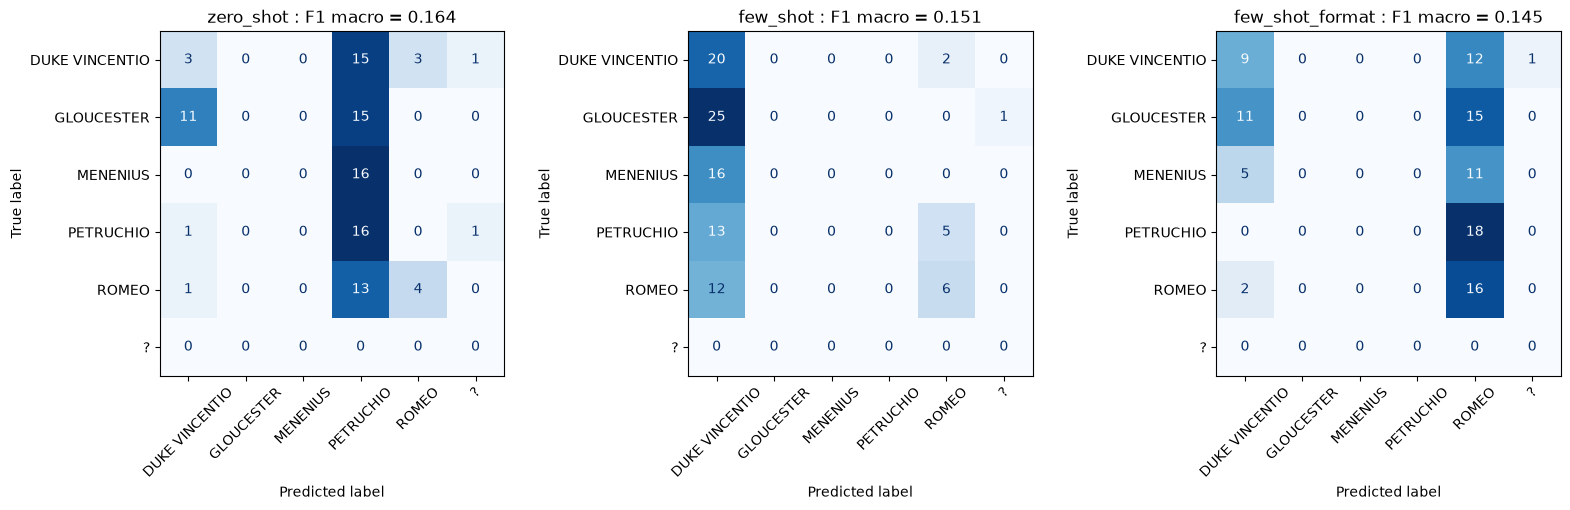

Meilleure stratégie : zero_shot

                precision    recall  f1-score   support

DUKE VINCENTIO      0.188     0.136     0.158        22
    GLOUCESTER      0.000     0.000     0.000        26
      MENENIUS      0.000     0.000     0.000        16
     PETRUCHIO      0.213     0.889     0.344        18
         ROMEO      0.571     0.222     0.320        18

     micro avg      0.235     0.230     0.232       100
     macro avg      0.194     0.249     0.164       100
  weighted avg      0.183     0.230     0.154       100



In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, s in zip(axes, STRATEGIES):
    sous = resultats[resultats["strategie"] == s]
    ConfusionMatrixDisplay.from_predictions(
        sous["vrai"], sous["predit"].fillna("?"), labels=LOCUTEURS + ["?"],
        xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(f"{s} : F1 macro = {tableau.loc[s, 'F1 (macro)']:.3f}")
plt.tight_layout()
plt.show()

meilleure = tableau["F1 (macro)"].idxmax()
sous = resultats[resultats["strategie"] == meilleure]
print(f"Meilleure stratégie : {meilleure}\n")
print(classification_report(sous["vrai"], sous["predit"].fillna("?"), labels=LOCUTEURS, digits=3, zero_division=0))

In [13]:
# scores des TP précédents, mesurés sur le test complet (153 répliques) : à recalculer sur les mêmes 100 répliques pour comparer vraiment
SCORES_PRECEDENTS = {
    "TP1 TF-IDF + LogisticRegression": 0.668,                  # train 608
    "TP1 TF-IDF + LinearSVC": 0.649,                           # train 608
    "TP2 TF-IDF + LogisticRegression (train 486)": 0.616,      # même train que le MLP
    "TP2 MLP (embedding appris, train 486)": 0.584,
    "TP2 baseline aléatoire stratifié": 0.215,
    "TP2 baseline classe majoritaire": 0.083,
}

# TF-IDF + LogisticRegression du TP1 (mêmes réglages), évaluée sur les 100 répliques posées au LLM
vec_tp1 = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.9, stop_words=None, sublinear_tf=True)
lr_tp1 = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
lr_tp1.fit(vec_tp1.fit_transform(X_train), y_train)
f1_test_complet = f1_score(y_test, lr_tp1.predict(vec_tp1.transform(X_test)), average="macro")
assert round(f1_test_complet, 3) == SCORES_PRECEDENTS["TP1 TF-IDF + LogisticRegression"], "le TP1 n'est pas retrouvé"
f1_meme_echantillon = f1_score(echantillon["locuteur"], lr_tp1.predict(vec_tp1.transform(echantillon["replique"])), average="macro")

comparaison = pd.concat([
    pd.Series(SCORES_PRECEDENTS, name="F1 macro"),
    pd.Series({"TP1 TF-IDF + LogisticRegression (mêmes répliques que le LLM)": f1_meme_echantillon}, name="F1 macro"),
    tableau["F1 (macro)"].rename(lambda s: f"TP3 {s} ({MODEL_NAME})").rename("F1 macro"),
]).to_frame()
comparaison["test"] = (["153 répliques"] * len(SCORES_PRECEDENTS)
                       + [f"{len(echantillon)} répliques"] * (1 + len(STRATEGIES)))
display(comparaison.round(3))


,F1 macro,test
TP1 TF-IDF + LogisticRegression,0.668,153 répliques
TP1 TF-IDF + LinearSVC,0.649,153 répliques
TP2 TF-IDF + LogisticRegression (train 486),0.616,153 répliques
"TP2 MLP (embedding appris, train 486)",0.584,153 répliques
TP2 baseline aléatoire stratifié,0.215,153 répliques
TP2 baseline classe majoritaire,0.083,153 répliques
TP1 TF-IDF + LogisticRegression (mêmes répliques que le LLM),0.670,100 répliques
TP3 zero_shot (qwen2.5:1.5b),0.164,100 répliques
TP3 few_shot (qwen2.5:1.5b),0.151,100 répliques
TP3 few_shot_format (qwen2.5:1.5b),0.145,100 répliques


> *Commentaire - 5 :*
> - Sur les mêmes 100 répliques, TF-IDF + LogisticRegression du TP 1 fait 0,670 de F1 macro, contre 0,145 à 0,164 pour le LLM.
> - Le LLM est même sous la baseline aléatoire du TP 2 (0,215).
> - La bonne référence est le TP 1 (train de 608) ; les lignes du TP 2 (train de 486) situent le MLP et les baselines.

## 6. Analyse

Quatre questions, une fois les 300 appels faits : 1. variabilité d'un run à l'autre (graine, température), 2. coût et temps, 3. erreurs typiques, 4. position face aux TP 1 et 2.

In [14]:
# extrapolation temps / coût : ce que ça donnerait sur tout le test, puis tout le corpus
extrap = tableau[["temps / réplique (s)", "coût estimé (USD)"]].copy()
extrap["temps 153 (min)"] = extrap["temps / réplique (s)"] * len(test) / 60
extrap["temps 761 (min)"] = extrap["temps / réplique (s)"] * len(donnees) / 60
extrap["coût 761 (USD)"] = extrap["coût estimé (USD)"] / len(echantillon) * len(donnees)
display(extrap.round(3))
# second run (graine 43, température 0,7) : fait sur une copie du notebook, résultats dans le commentaire 6

,temps / réplique (s),coût estimé (USD),temps 153 (min),temps 761 (min),coût 761 (USD)
stratégie,,,,,
zero_shot,0.360,0.003,0.919,4.569,0.020
few_shot,0.265,0.007,0.677,3.367,0.053
few_shot_format,0.187,0.007,0.476,2.367,0.054


In [15]:
# ce que le modèle répond vraiment : répartition des classes prédites, et incertitude sur l'accuracy (100 répliques)
repartition = (resultats.assign(predit=resultats["predit"].fillna("?"))
               .pivot_table(index="strategie", columns="predit", values="id_replique", aggfunc="count", fill_value=0)
               .reindex(index=STRATEGIES, columns=LOCUTEURS + ["?"], fill_value=0))
display(repartition)

for s in STRATEGIES:
    sous = resultats[resultats["strategie"] == s]
    bonnes = int((sous["vrai"] == sous["predit"]).sum())
    ic = binomtest(bonnes, len(sous)).proportion_ci()
    print(f"{s:16s} accuracy {bonnes / len(sous):.2f}   IC à 95 % [{ic.low:.2f} ; {ic.high:.2f}]")
print("Hasard uniforme sur 5 classes : accuracy 0.20")

predit,DUKE VINCENTIO,GLOUCESTER,MENENIUS,PETRUCHIO,ROMEO,?
strategie,,,,,,
zero_shot,16,0,0,75,7,2
few_shot,86,0,0,0,13,1
few_shot_format,27,0,0,0,72,1


zero_shot        accuracy 0.23   IC à 95 % [0.15 ; 0.32]
few_shot         accuracy 0.26   IC à 95 % [0.18 ; 0.36]
few_shot_format  accuracy 0.25   IC à 95 % [0.17 ; 0.35]
Hasard uniforme sur 5 classes : accuracy 0.20


> *Commentaire - 6 : bilan de la partie 6*
> - Variabilité : à `TEMPERATURE = 0`, changer la graine ne change rien (les 300 réponses sont identiques).
> - Variabilité : à 0,7, tout change (46/100, 1/100 et 70/100 prédictions identiques) et l'ordre des stratégies s'inverse. L'écart entre stratégies à T = 0 (0,02 au plus) ne veut donc rien dire.
> - Coût : 136, 446 et 465 tokens par réplique, et 0,36, 0,27 et 0,19 s en local. Le corpus prendrait 4,6, 3,4 et 2,4 min et coûterait 0,020, 0,053 et 0,054 USD au tarif d'une petite API, contre 39 ms pour entraîner la LogisticRegression.
> - Erreurs : le modèle répond presque toujours la même classe (75 % PETRUCHIO en zero-shot, 86 % DUKE VINCENTIO en few-shot, 72 % ROMEO en few-shot + format). GLOUCESTER et MENENIUS ne sont jamais prédits.
> - Hasard : l'accuracy (0,23 à 0,26) a un intervalle à 95 % qui contient le hasard (0,20), donc je ne peux pas dire que le modèle lit la réplique.
> - TP 1 et 2 : 0,670 pour TF-IDF + LogisticRegression contre 0,145 à 0,164 pour le LLM. Le modèle classique apprend sur 608 répliques étiquetées et le signal est surtout lexical, alors que le LLM n'a que 10 exemples. C'est le cas de la diapo 88 : une tâche étroite avec des labels, où la brique la plus simple suffit.
>
> Limites : un seul petit modèle (1,5 milliard de paramètres), des prompts en anglais, 100 répliques. Les runs à `SEED_MODELE = 43` et à `TEMPERATURE = 0.7` ont été faits sur une copie du notebook et ne sont pas versionnés.

## 7. Consignes du sujet

| Consigne | Où |
|---|---|
| Prompting : trois stratégies, exemples tirés du train | partie 2 |
| Modèle LLM : fournisseur, paramètres, cache | partie 3 |
| Sortie générée : parsing, réponses non parsées comptées | partie 4 |
| Évaluation : accuracy, précision, rappel, F1, matrice de confusion, coût | partie 5 |
| Comparaison aux TP 1 et 2, variabilité, erreurs | parties 5 et 6 |